In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (semanas) se adjunta. Cada actividad necesita un número de operarios y, algunas, una máquina excavadora (columna *machines*). El jefe de obra propone retrasar H 2 semana(s) y B 1 semana(s) para suavizar la demanda de operarios.

In [4]:
pregunta_1 = "1. Dibuje los diagramas de cargas de operarios y de máquinas con las actividades en su inicio más temprano. ¿Cuántas máquinas hacen falta como máximo?  "
pregunta_2 = "2. Evalúe la propuesta del jefe de obra: ¿respeta las holguras? ¿Reduce la suma de cuadrados de las cargas de operarios?  "
pregunta_3 = "3. Compare la propuesta con el resultado del algoritmo de nivelación. ¿Cuál es mejor?  "
pregunta_4 = "4. ¿Qué ocurre con la carga de máquinas tras la nivelación de operarios? ¿Puede una nivelación empeorar el otro recurso?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje los diagramas de cargas de operarios y de máquinas con las actividades en su inicio más temprano. ¿Cuántas máquinas hacen falta como máximo?  

2. Evalúe la propuesta del jefe de obra: ¿respeta las holguras? ¿Reduce la suma de cuadrados de las cargas de operarios?  

3. Compare la propuesta con el resultado del algoritmo de nivelación. ¿Cuál es mejor?  

4. ¿Qué ocurre con la carga de máquinas tras la nivelación de operarios? ¿Puede una nivelación empeorar el otro recurso?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources, machines
    ('A'     , '---'      , 2       , 4        , 2       ),
    ('B'     , '---'      , 7       , 1        , 0       ),
    ('C'     , 'A'        , 4       , 4        , 0       ),
    ('D'     , 'C'        , 2       , 2        , 2       ),
    ('E'     , 'D'        , 8       , 4        , 0       ),
    ('F'     , 'B,D'      , 1       , 4        , 2       ),
    ('G'     , 'F'        , 8       , 4        , 2       ),
    ('H'     , 'F'        , 7       , 1        , 1       ),
    ('I'     , 'E,G'      , 3       , 1        , 2       ),
], columns=['activity', 'predecessor', 'duration', 'resources', 'machines']).set_index('activity')
datos_enunciado

,predecessor,duration,resources,machines
activity,,,,
A,---,2,4,2
B,---,7,1,0
C,A,4,4,0
D,C,2,2,2
E,D,8,4,0
F,"B,D",1,4,2
G,F,8,4,2
H,F,7,1,1
I,"E,G",3,1,2


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje los diagramas de cargas de operarios y de máquinas con las actividades en su inicio más temprano. ¿Cuántas máquinas hacen falta como máximo?  

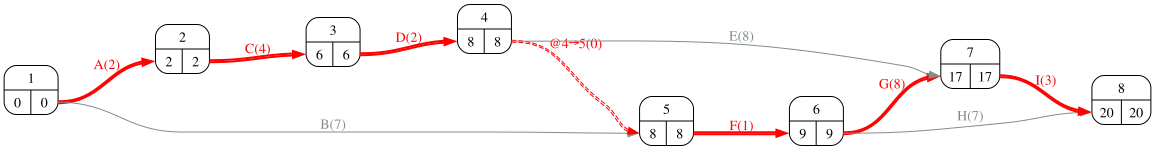

In [8]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

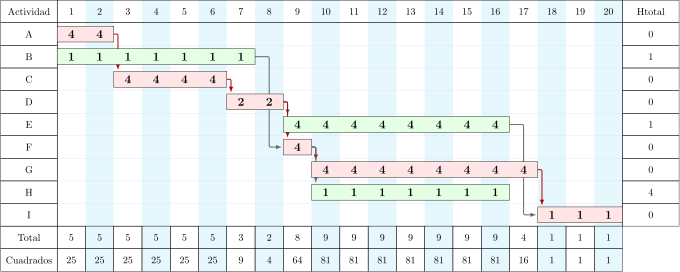

In [9]:
#| fig-cap: "Diagrama de Gantt con las cargas de operarios (inicios más tempranos)"
#| label: fig-ganttInicial
proyecto_inicial = proyecto.copy()
gantt_inicial, dibujo = proyecto_inicial.gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

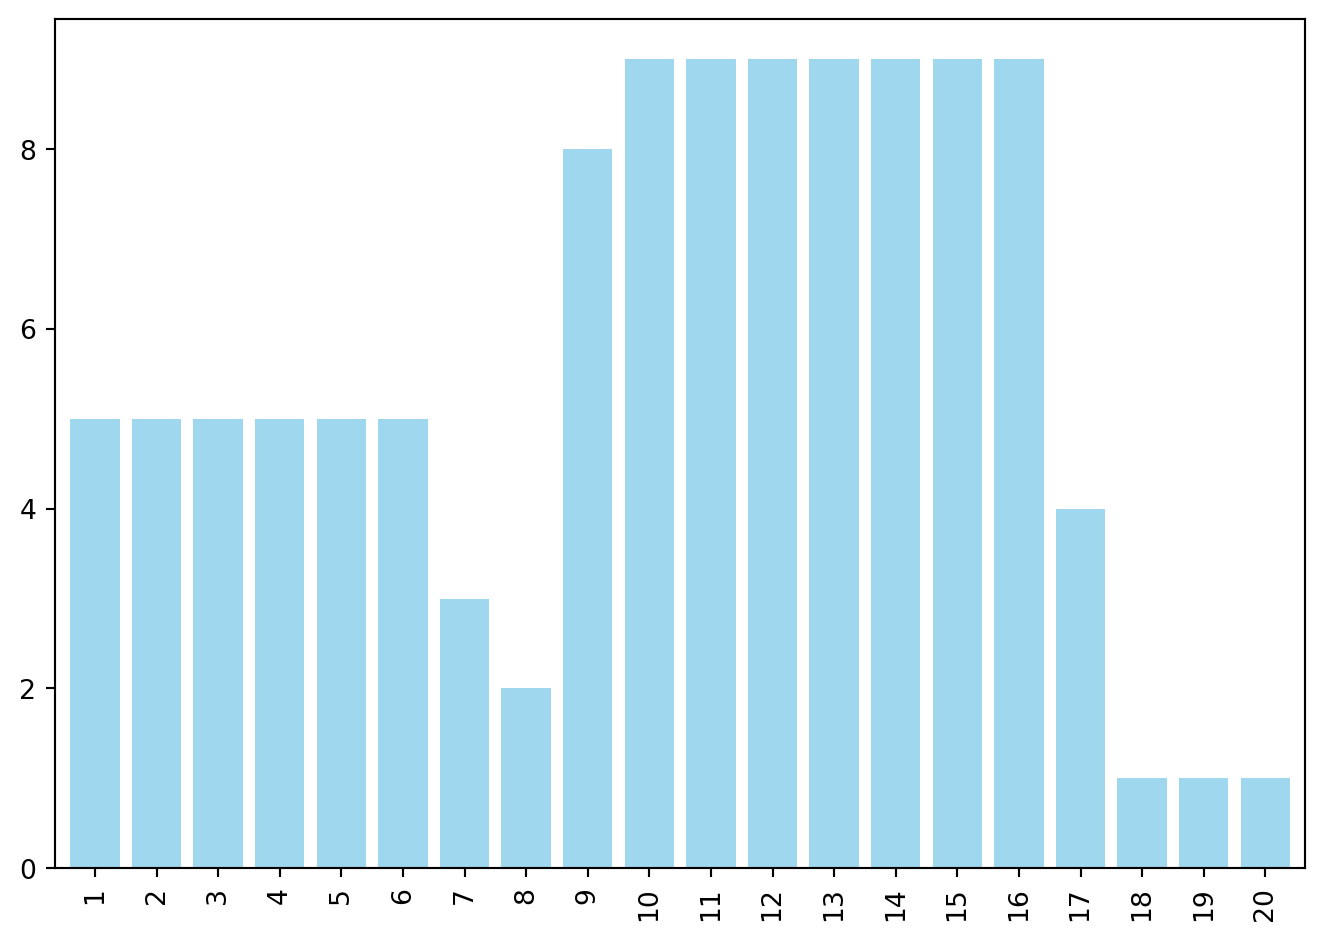

In [10]:
#| fig-cap: "Diagrama de cargas de operarios"
#| label: fig-cargasInicial
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=None)

In [11]:
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
semanas_pico = cargas.index[cargas == cargas.max()].tolist()
Markdown(f'El máximo de operarios es {int(cargas.max())}, en las semanas {", ".join(map(str, semanas_pico))}. '
         f'La media es {cargas.mean():.2f} operarios/semana.')

El máximo de operarios es 9, en las semanas 10, 11, 12, 13, 14, 15, 16. La media es 5.65 operarios/semana.

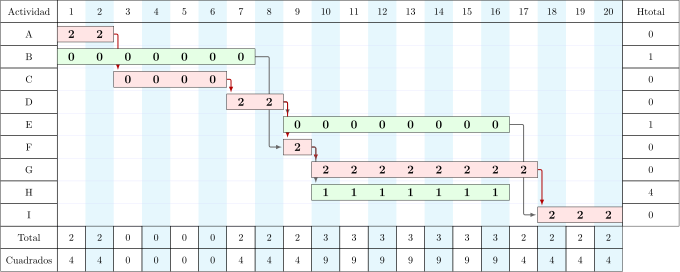

In [12]:
#| fig-cap: "Diagrama de Gantt con las cargas de máquinas"
#| label: fig-ganttMaquinas
gantt_maquinas, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'machines', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

In [13]:
cargas_maquinas = gantt_maquinas.data.loc['Total'].drop('H_total').astype(float)
Markdown(f'Hacen falta como máximo {int(cargas_maquinas.max())} máquina(s).')

Hacen falta como máximo 3 máquina(s).

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. Evalúe la propuesta del jefe de obra: ¿respeta las holguras? ¿Reduce la suma de cuadrados de las cargas de operarios?  

In [15]:
holguras = proyecto.calendar(datos_proyecto['duration'])['H_total']
propuesta = {'H': 2, 'B': 1}
pd.DataFrame({'desplazamiento propuesto': pd.Series(propuesta), 'holgura total': holguras[list(propuesta)]})

,desplazamiento propuesto,holgura total
H,2,4
B,1,1


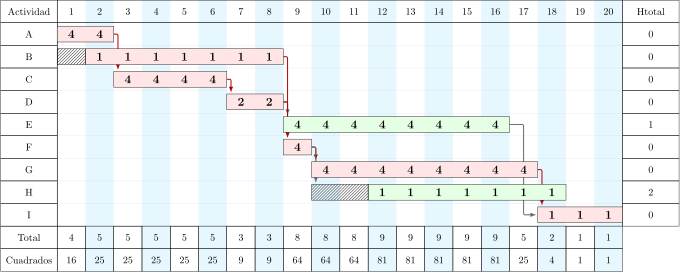

In [16]:
#| fig-cap: "Diagrama de Gantt con la propuesta del jefe de obra"
#| label: fig-ganttPropuesta
suma_cuadrados_inicial = float((cargas ** 2).sum())
proyecto_propuesta = proyecto.copy()
suma_cuadrados_propuesta, _ = proyecto_propuesta.evaluar_desplazamiento(
    datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=False, **propuesta)
_, _, dibujo = proyecto.copy().desplazar(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True,
                                         params=GANTT_PARAMS, **propuesta)
pinta_tikz(dibujo)

In [17]:
Markdown(f'La propuesta respeta las holguras (cada desplazamiento es menor o igual que la holgura total) y la suma de cuadrados '
         f'pasa de {suma_cuadrados_inicial:.0f} a {suma_cuadrados_propuesta:.0f}: '
         f'{"mejora" if suma_cuadrados_propuesta < suma_cuadrados_inicial else "no mejora"} el nivelado.')

La propuesta respeta las holguras (cada desplazamiento es menor o igual que la holgura total) y la suma de cuadrados pasa de 813 a 787: mejora el nivelado.

## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. Compare la propuesta con el resultado del algoritmo de nivelación. ¿Cuál es mejor?  

In [19]:
#| tbl-cap: "Desplazamientos del algoritmo de nivelación"
#| label: tbl-desplazamientos
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources')
desplazamientos[desplazamientos['desplazamientos'] > 0]

,desplazamientos
B,1
H,4


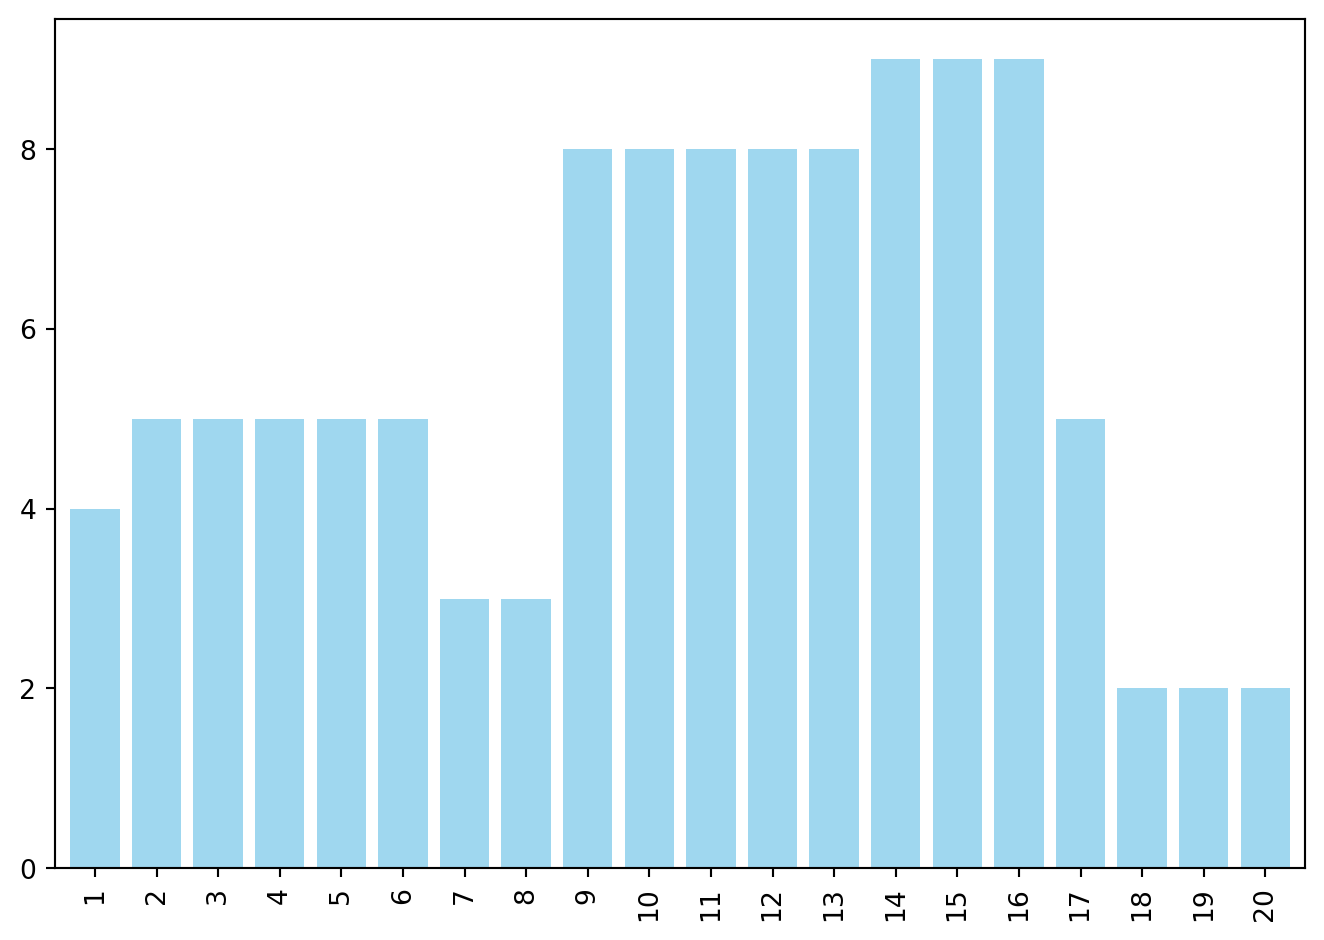

In [20]:
#| fig-cap: "Diagrama de cargas de operarios tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=None)

In [21]:
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
suma_cuadrados_nivelado = float((cargas_niveladas ** 2).sum())
pd.DataFrame({'suma de cuadrados': [suma_cuadrados_inicial, suma_cuadrados_propuesta, suma_cuadrados_nivelado],
              'máximo de operarios': [cargas.max(), None, cargas_niveladas.max()]},
             index=['inicial', 'propuesta del jefe de obra', 'nivelación'])

,suma de cuadrados,máximo de operarios
inicial,813.0,9.0
propuesta del jefe de obra,787.0,NaN
nivelación,759.0,9.0


In [22]:
Markdown(f'El algoritmo de nivelación {"mejora" if suma_cuadrados_nivelado < suma_cuadrados_propuesta else "no mejora"} la propuesta: '
         f'prueba sistemáticamente todos los desplazamientos de cada actividad no crítica, aunque, al hacerlo actividad a actividad, tampoco garantiza el óptimo global.')

El algoritmo de nivelación mejora la propuesta: prueba sistemáticamente todos los desplazamientos de cada actividad no crítica, aunque, al hacerlo actividad a actividad, tampoco garantiza el óptimo global.

## Apartado 4

In [23]:
display(Markdown(pregunta_4))

4. ¿Qué ocurre con la carga de máquinas tras la nivelación de operarios? ¿Puede una nivelación empeorar el otro recurso?  

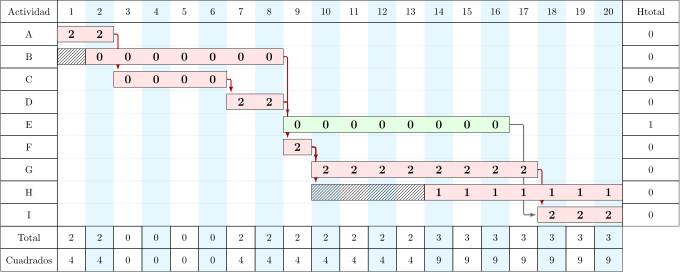

In [24]:
#| fig-cap: "Cargas de máquinas tras la nivelación de operarios"
#| label: fig-maquinasNivelado
datos_maquinas = datos_nivelados.copy()
datos_maquinas['machines'] = datos_proyecto['machines'].reindex(datos_maquinas.index).fillna(0).astype(int)
gantt_maquinas_niv, dibujo = proyecto_nivelado.copy().gantt_cargas(datos_maquinas, 'duration', 'machines', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

In [25]:
cargas_maquinas_niv = gantt_maquinas_niv.data.loc['Total'].drop('H_total').astype(float)
pd.DataFrame({'antes': [cargas_maquinas.max(), (cargas_maquinas ** 2).sum()],
              'después': [cargas_maquinas_niv.max(), (cargas_maquinas_niv ** 2).sum()]},
             index=['máximo de máquinas', 'suma de cuadrados (máquinas)']).astype(int)

,antes,después
máximo de máquinas,3,3
suma de cuadrados (máquinas),99,99


La nivelación optimiza un único recurso; los desplazamientos que allanan la demanda de operarios pueden concentrar la de máquinas. Con varios recursos hay que nivelar con una función objetivo combinada o comprobar cada recurso tras nivelar el principal.